In [1]:
import pandas as pd
import numpy as np
import mlflow
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score
import optuna
import shap
import matplotlib.pyplot as plt

mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("Modeling")

c:\Users\DELL\Desktop\Projet Data\Data Science\.datascience\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<Experiment: artifact_location='mlflow-artifacts:/3', creation_time=1785101030275, effective_trace_archival_retention=None, experiment_id='3', last_update_time=1785101030275, lifecycle_stage='active', name='Modeling', tags={}, trace_location=None, workspace='default'>

In [2]:
path = "../data/processed/Bank_Churn_clean.csv"
df = pd.read_csv(path)


TARGET = "Exited"
X = df.drop(columns=[TARGET])
y = df["Exited"]

X_train, X_test, y_train, y_test = train_test_split(X, y , test_size = 0.2, stratify= y, random_state=42)


ohe = OneHotEncoder( handle_unknown='ignore')
cat_cols = ['Gender', 'Geography']

ohe.fit(X_train[cat_cols])
X_train_ohe = ohe.transform(X_train[cat_cols])
X_test_ohe = ohe.transform(X_test[cat_cols])

ohe_cols = ohe.get_feature_names_out(cat_cols)
X_train[ohe_cols] = pd.DataFrame(X_train_ohe.toarray(), columns=ohe_cols, index=X_train.index)
X_test[ohe_cols] = pd.DataFrame(X_test_ohe.toarray(), columns=ohe_cols, index=X_test.index)

X_train = X_train.drop(columns=cat_cols)
X_test = X_test.drop(columns=cat_cols)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [14]:
mlflow.sklearn.autolog()


def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 600),
        'max_depth': trial.suggest_int('max_depth', 3, 15),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features': trial.suggest_categorical('max_features', [None, 'sqrt', 'log2']),
        'min_samples_split': trial.suggest_int('min_samples_split',2,10),
        'random_state': 42
    }

    with mlflow.start_run(nested=True):
        model = RandomForestClassifier(**params)
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        recall = recall_score(y_test, y_pred)
        return recall


with mlflow.start_run():
    study = optuna.create_study(direction="maximize")
    study.optimize(objective, n_trials=20)

    mlflow.log_params({f"best_{k}": v for k, v in study.best_params.items()})
    mlflow.log_metric("best_recall", study.best_value)

[I 2026-07-27 01:15:04,873] A new study created in memory with name: no-name-ca68a1af-b618-430b-bc26-bbe31f98a877
2026/07/27 01:15:04 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Tracking. Reason: 'Series' object has no attribute 'flatten'
2026/07/27 01:15:06 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\DELL\Desktop\Projet Data\Data Science\.datascience\Lib\site-packages\sklearn\metrics\_classification.py:3424: FutureWarning: `y_pred` was renamed to `y_proba` in version 1.9 and will be removed in 1.11. Use `y_proba` instead.
  warnings.warn(
[I 2026-07-27 01:15:15,699] Trial 0 finished with value: 0.4447174447174447

🏃 View run whimsical-crane-363 at: http://localhost:5000/#/experiments/3/runs/c5e717190e0448bebd069a3fa6171e60
🧪 View experiment at: http://localhost:5000/#/experiments/3


2026/07/27 01:15:24 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\DELL\Desktop\Projet Data\Data Science\.datascience\Lib\site-packages\sklearn\metrics\_classification.py:3424: FutureWarning: `y_pred` was renamed to `y_proba` in version 1.9 and will be removed in 1.11. Use `y_proba` instead.
  warnings.warn(
[I 2026-07-27 01:15:35,834] Trial 1 finished with value: 0.457002457002457 and parameters: {'n_estimators': 392, 'max_depth': 9, 'min_samples_leaf': 5, 'max_features': None, 'min_samples_split': 10}. Best is trial 1 with value: 0.457002457002457.
2026/07/27 01:15:35 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Tra

🏃 View run clumsy-mink-84 at: http://localhost:5000/#/experiments/3/runs/5e2175dda6cd4904b6c715c40a92f40a
🧪 View experiment at: http://localhost:5000/#/experiments/3


2026/07/27 01:15:37 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\DELL\Desktop\Projet Data\Data Science\.datascience\Lib\site-packages\sklearn\metrics\_classification.py:3424: FutureWarning: `y_pred` was renamed to `y_proba` in version 1.9 and will be removed in 1.11. Use `y_proba` instead.
  warnings.warn(
[I 2026-07-27 01:15:47,145] Trial 2 finished with value: 0.4152334152334152 and parameters: {'n_estimators': 239, 'max_depth': 8, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'min_samples_split': 4}. Best is trial 1 with value: 0.457002457002457.
2026/07/27 01:15:47 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow 

🏃 View run capable-cub-430 at: http://localhost:5000/#/experiments/3/runs/450eae43bd7544568ea3af5db1178e9a
🧪 View experiment at: http://localhost:5000/#/experiments/3


... (30 outputs left out)

2026/07/27 01:20:45 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\DELL\Desktop\Projet Data\Data Science\.datascience\Lib\site-packages\sklearn\metrics\_classification.py:3424: FutureWarning: `y_pred` was renamed to `y_proba` in version 1.9 and will be removed in 1.11. Use `y_proba` instead.
  warnings.warn(
[I 2026-07-27 01:20:56,065] Trial 18 finished with value: 0.4594594594594595 and parameters: {'n_estimators': 382, 'max_depth': 11, 'min_samples_leaf': 6, 'max_features': None, 'min_samples_split': 8}. Best is trial 4 with value: 0.47174447174447176.
2026/07/27 01:20:56 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow

🏃 View run useful-panda-122 at: http://localhost:5000/#/experiments/3/runs/6ab07af70e8244a68848ca5a2d40d9b6
🧪 View experiment at: http://localhost:5000/#/experiments/3


2026/07/27 01:21:08 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\DELL\Desktop\Projet Data\Data Science\.datascience\Lib\site-packages\sklearn\metrics\_classification.py:3424: FutureWarning: `y_pred` was renamed to `y_proba` in version 1.9 and will be removed in 1.11. Use `y_proba` instead.
  warnings.warn(
[I 2026-07-27 01:21:19,373] Trial 19 finished with value: 0.4520884520884521 and parameters: {'n_estimators': 443, 'max_depth': 14, 'min_samples_leaf': 9, 'max_features': None, 'min_samples_split': 9}. Best is trial 4 with value: 0.47174447174447176.


🏃 View run indecisive-squid-209 at: http://localhost:5000/#/experiments/3/runs/be47fe8a4dcb42569efa324194b6303e
🧪 View experiment at: http://localhost:5000/#/experiments/3
🏃 View run tasteful-tern-255 at: http://localhost:5000/#/experiments/3/runs/8766fa308e844028b897dd797e67247c
🧪 View experiment at: http://localhost:5000/#/experiments/3


In [15]:
best_params = study.best_params
print("Meilleurs hyperparamètres:", best_params)

Meilleurs hyperparamètres: {'n_estimators': 450, 'max_depth': 14, 'min_samples_leaf': 5, 'max_features': None, 'min_samples_split': 7}


In [5]:
model_name = "Rf_churn"
model_version = "Version 1"
model_uri = f"models:/{model_name}/{model_version}"
# Normalize model_version (accept "Version 1", "1", or stage names)
mv = model_version
if isinstance(mv, str) and mv.lower().startswith("version "):
    mv = mv.split(" ", 1)[1].strip()

# Map stage names to proper case
stage_map = {"staging": "Staging", "production": "Production", "archived": "Archived"}

if isinstance(mv, str) and mv.isdigit():
    model_uri = f"models:/{model_name}/{mv}"
elif isinstance(mv, str) and mv.lower() in stage_map:
    model_uri = f"models:/{model_name}/{stage_map[mv.lower()]}"
else:
    raise ValueError(f"Invalid model_version '{model_version}'. Use numeric version (e.g. '1'), 'Version 1', or stage: Staging/Production/Archived.")

model = mlflow.sklearn.load_model(model_uri)

In [6]:
# 3. Calcul des valeurs SHAP
# TreeExplainer est optimisé pour les modèles d'arbres comme Random Forest
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)

# En classification binaire, SHAP génère des valeurs pour la classe 0 et la classe 1.
# On sélectionne les valeurs pour la classe 1 (généralement la classe positive).
shap_values_class1 = shap_values[:, :, 1]


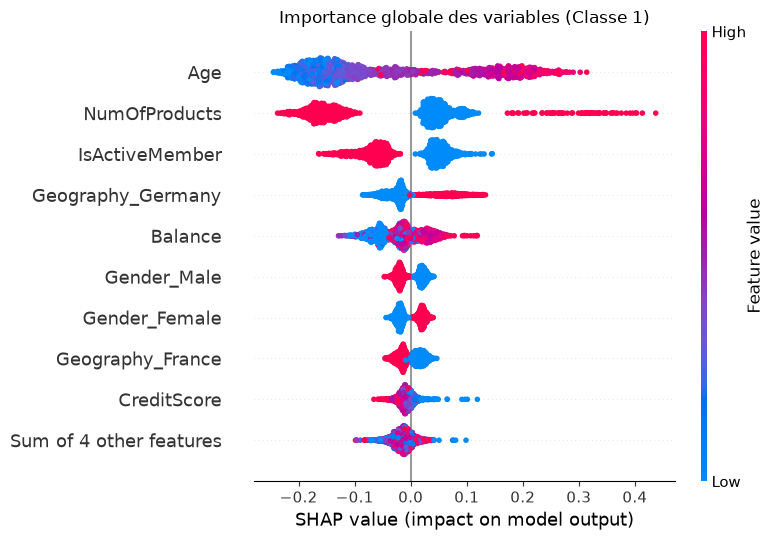

In [7]:
# 4. Génération des visualisations
# Graphique 1 : Résumé global (Beeswarm)
plt.figure()
shap.plots.beeswarm(shap_values_class1, show=False)
plt.title("Importance globale des variables (Classe 1)")
plt.tight_layout()
plt.show()

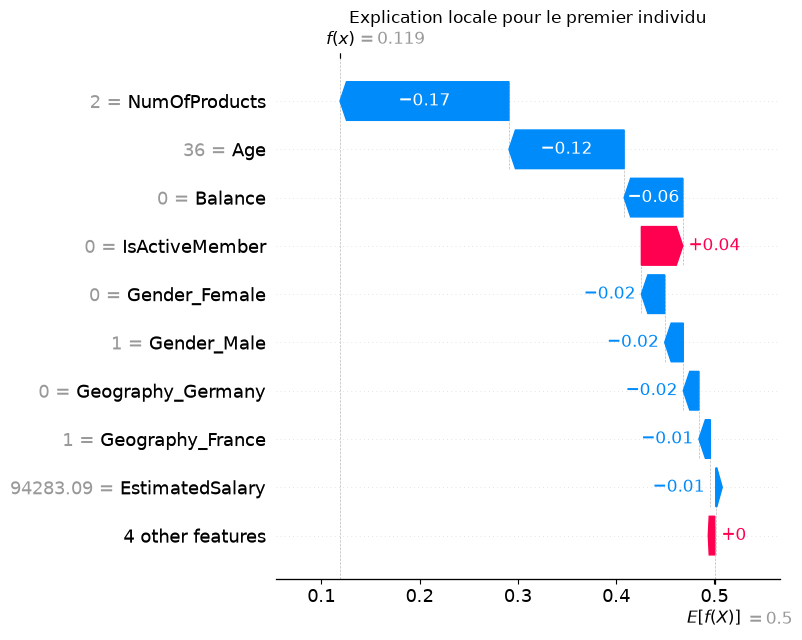

In [8]:
# Graphique 2 : Explication locale (Waterfall pour le 1er individu)
plt.figure()
shap.plots.waterfall(shap_values_class1[0], show=False)
plt.title("Explication locale pour le premier individu")
plt.tight_layout()
plt.show()